# Installing a new piecewise response

Add a specified response to an existing fitted checkpoint by writing one hidden unit and its outgoing weight.

Suppose the original model should keep its response up to x = 0.4 and then acquire an extra slope of 0.85. The added function is one hinge, 0.85 × max(0, x − 0.4). Append one weight, bias and readout coefficient. Copy the original units exactly. This small weight-space program has an explicit installation target and a region in which its effect must be zero.

In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory
import numpy as np
import matplotlib.pyplot as plt


def response(model, x):
    hidden = np.maximum(0, x[:, None] * model["weights"] + model["biases"])
    return model["offset"] + hidden @ model["out"]


def install(checkpoint, output, threshold, slope):
    with np.load(checkpoint, allow_pickle=False) as data:
        weights = {k: data[k] for k in ["weights", "biases", "out", "offset"]}
    if weights["weights"].ndim != 1 or any(
        weights[k].shape != weights["weights"].shape for k in ["biases", "out"]
    ):
        raise ValueError("Expected a scalar-input, scalar-output hidden layer")
    np.savez(
        output,
        weights=np.r_[weights["weights"], 1.0],
        biases=np.r_[weights["biases"], -threshold],
        out=np.r_[weights["out"], slope],
        offset=weights["offset"],
    )

## Fit a baseline, write the patch and reload both checkpoints

Only the baseline fit uses labelled data. The installation program reads the saved weights and writes the new checkpoint. Its only additional inputs are the requested threshold and slope.

In [2]:
rng = np.random.default_rng(97)
xtrain = np.sort(rng.uniform(-2.0, 2.0, 150))
target = (
    0.3
    + 0.45 * xtrain
    + 0.4 * np.maximum(0, xtrain + 0.3)
    - 0.5 * np.maximum(0, xtrain - 0.8)
    + rng.normal(0, 0.05, len(xtrain))
)
w = np.array([1.0, -1.0, 1.0, 1.0])
b = np.array([0.0, 0.0, 0.3, -0.8])
features = np.maximum(0, xtrain[:, None] * w + b)
coef = np.linalg.lstsq(np.column_stack((np.ones(len(xtrain)), features)), target, rcond=None)[0]
threshold = 0.4
slope = 0.85
with TemporaryDirectory() as directory:
    folder = Path(directory)
    old = folder / "base.npz"
    new = folder / "installed.npz"
    np.savez(old, weights=w, biases=b, out=coef[1:], offset=coef[0])
    install(old, new, threshold, slope)
    with np.load(old, allow_pickle=False) as archived:
        base = {k: archived[k] for k in archived.files}
    with np.load(new, allow_pickle=False) as archived:
        patched = {k: archived[k] for k in archived.files}
for field in ["weights", "biases", "out"]:
    np.testing.assert_array_equal(patched[field][:-1], base[field])
print("Hidden units before and after", len(base["weights"]), len(patched["weights"]))
print("New unit", patched["weights"][-1], patched["biases"][-1], patched["out"][-1])

Hidden units before and after 4 5
New unit 1.0 -0.4 0.85


## Measure installation error and off-region drift

Draw independent inputs on both sides and include the threshold itself. Compare the change with the piecewise specification, separately checking the unaffected region.

Change RMSE 9.57e-17 | maximum off-region drift 0


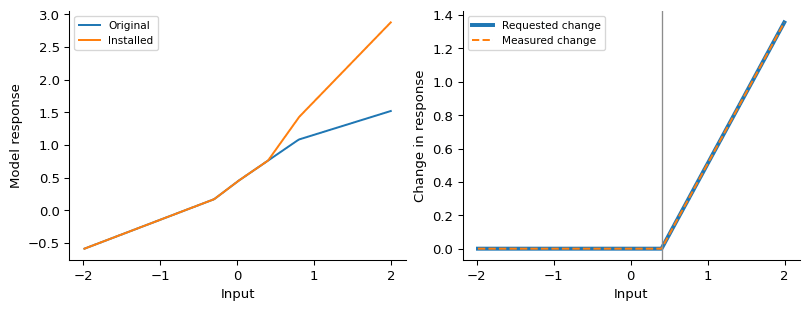

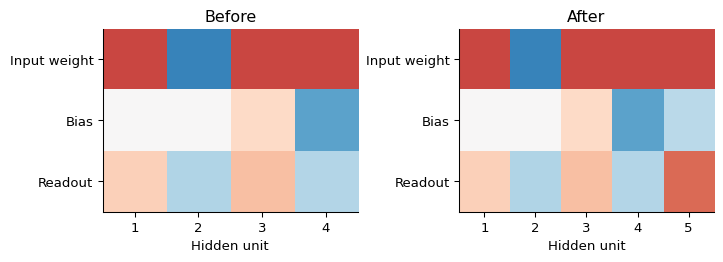

In [3]:
test = np.sort(np.r_[rng.uniform(-2, 2, 500), threshold])
before = response(base, test)
after = response(patched, test)
wanted = np.where(test > threshold, slope * (test - threshold), 0.0)
change = after - before
rmse = np.sqrt(np.mean((change - wanted) ** 2))
off = np.max(abs(change[test <= threshold]))
print(f"Change RMSE {rmse:.3g} | maximum off-region drift {off:.3g}")
assert rmse < 1e-12 and off < 1e-12
fig, (a, b) = plt.subplots(1, 2, figsize=(8.4, 3.15), constrained_layout=True)
a.plot(test, before, label="Original")
a.plot(test, after, label="Installed")
a.set(xlabel="Input", ylabel="Model response")
a.legend(fontsize=8)
b.plot(test, wanted, label="Requested change", lw=3)
b.plot(test, change, "--", label="Measured change")
b.axvline(threshold, color="0.55", lw=1)
b.set(xlabel="Input", ylabel="Change in response")
b.legend(fontsize=8)
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(7.5, 2.65), constrained_layout=True)
for ax, model, label in zip(axes, [base, patched], ["Before", "After"]):
    values = np.stack([model[k] for k in ["weights", "biases", "out"]])
    ax.imshow(values, cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
    ax.set(
        yticks=[0, 1, 2],
        yticklabels=["Input weight", "Bias", "Readout"],
        xticks=range(values.shape[1]),
        xticklabels=np.arange(1, values.shape[1] + 1),
        xlabel="Hidden unit",
        title=label,
    )
plt.show()

## Interpreting the result

The output displacement matches the specification to floating-point precision. Architectural expansion was allowed in this example. Installing the same change in a network of fixed width would require a spare unit or another representation. The construction is a small independent example of direct weight programming.

## Exercise

Install a bounded triangular response using three hinges. Verify equality before the first knot and after the last one.

## References

[WeightCode, installing capabilities through weight-space programming](https://arxiv.org/abs/2611.25476)

[Unser, a representer theorem for deep neural networks](https://www.jmlr.org/papers/v20/18-418.html)